In [26]:

import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
%matplotlib ipympl
import seaborn as sns

Esse notebook irá realizar um redução de dimensionalidade nos dados, primeiro foi feito uma padronização nos dados com StandardScaler e após isso foi gerada o metodo cotovelo para ver quantas dimensões seria melhor (manteria a maior variança com menos componentes) para o PCA.

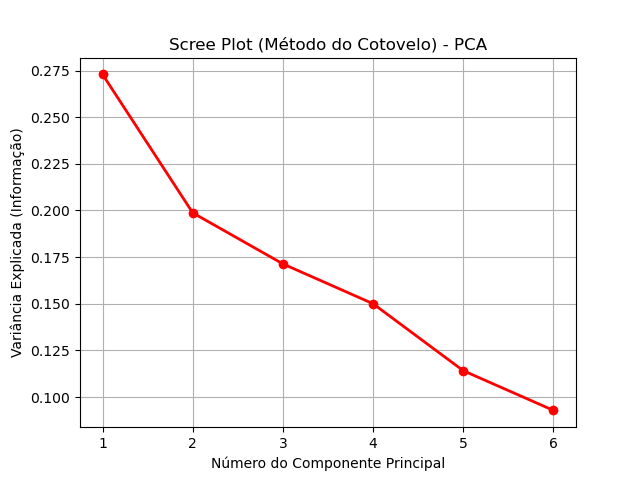

Variância acumulada nos primeiros 10 componentes:
[0.27292621 0.47166111 0.64302284 0.79303156 0.90715425 1.        ]


In [27]:
df = pd.read_csv("StudentStress.csv")

X_std = StandardScaler().fit_transform(df)

pca = PCA().fit(X_std)


variancia_explicada = pca.explained_variance_ratio_



plt.figure(1)
plt.clf()

componentes = np.arange(1, len(variancia_explicada) + 1)

plt.plot(componentes, variancia_explicada, 'ro-', linewidth=2)

plt.title('Scree Plot (Método do Cotovelo) - PCA')
plt.xlabel('Número do Componente Principal')
plt.ylabel('Variância Explicada (Informação)')
plt.xticks(componentes) 
plt.grid(True)
plt.show()


print("Variância acumulada nos primeiros 10 componentes:")
print(np.cumsum(pca.explained_variance_ratio_)[:10])

A análise de correlações foi conduzida para identificar relações entre os atributos dos estudantes. Observa-se que coeficientes próximos à unidade positiva (+1) denotam uma forte associação direta, enquanto aqueles próximos à unidade negativa (-1) representam uma forte associação inversa. Por outro lado, coeficientes próximos de zero evidenciam uma independência linear entre as variáveis analisadas.

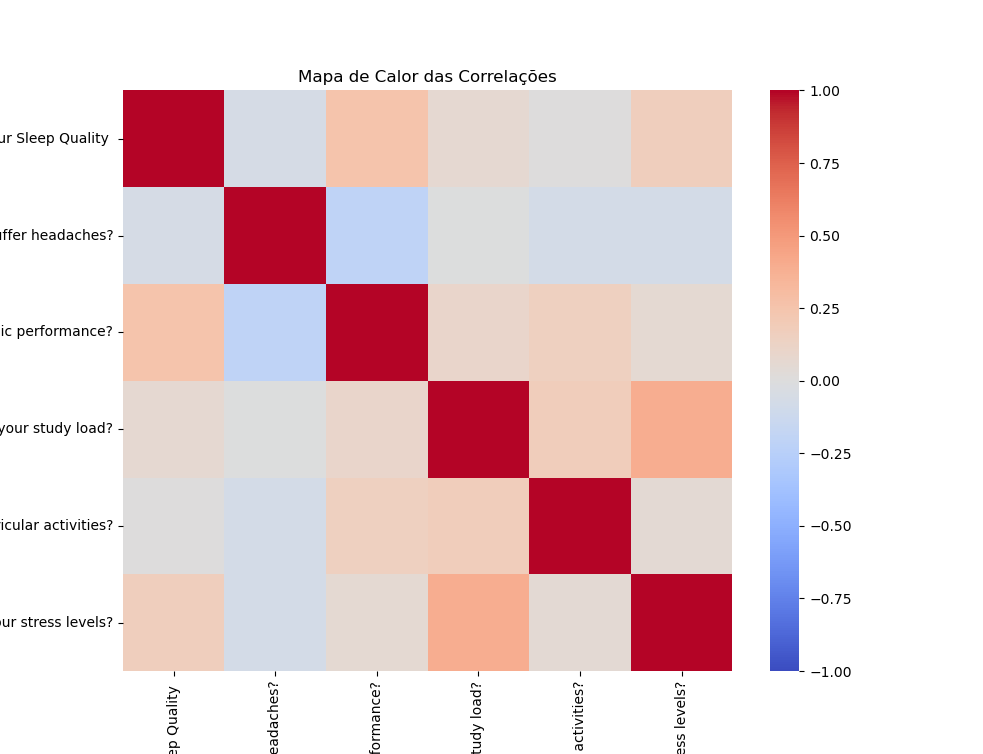

In [28]:


# Vamos ver se existe correlação nos dados brutos
plt.figure(2)
plt.clf()

# Use o df (com as colunas numéricas), não o X_std
sns.heatmap(df.corr(), annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Mapa de Calor das Correlações")
plt.show()

O PCA foi gerado após a remoção da coluna 'how would you rate your study load?'. Isso garantiu que o agrupamento dos alunos ocorresse sem a influência dessa variável, a qual foi utilizada posteriormente para a validação e caracterização dos grupos. A pergunta seria "Será que os alunos que se sentem sobrecarregados (Carga de Estudo alta) têm hábitos e sintomas físicos diferentes dos outros?"

Dimensões originais dos dados: (520, 5)
Dimensões após o PCA: (520, 2)


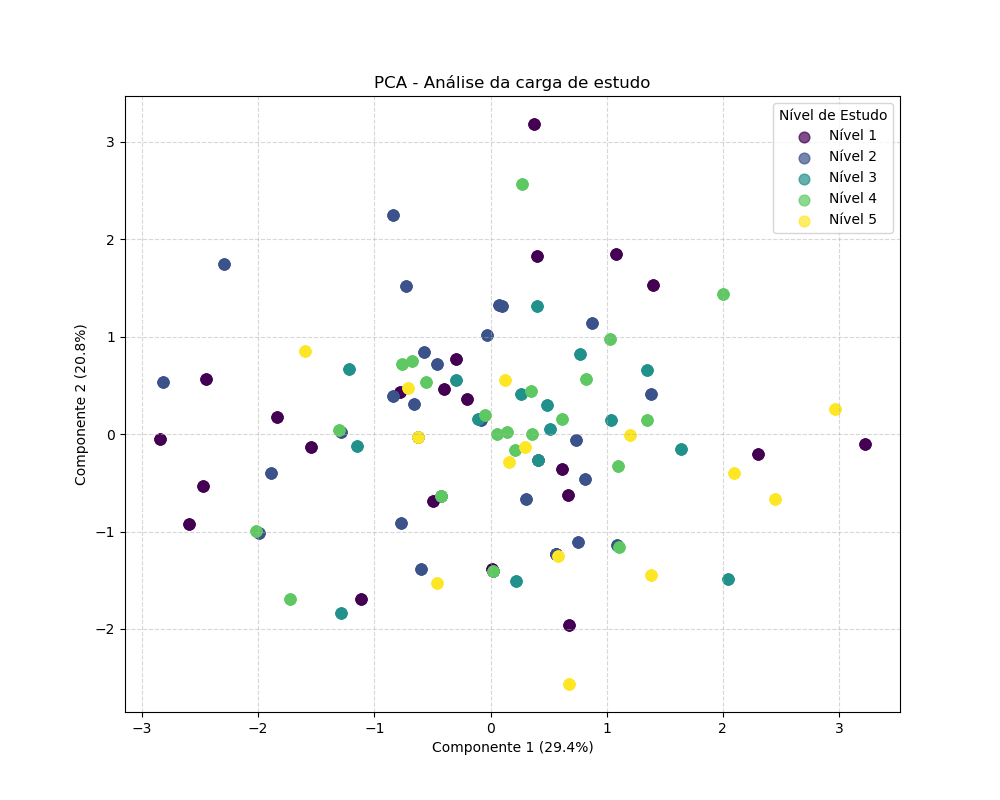

Informação total preservada: 50.13%


In [30]:

X = df.drop(columns=['how would you rate your study load?'], errors='ignore')

y = df['how would you rate your study load?']
print(f"Dimensões originais dos dados: {X.shape}") 

X_std = StandardScaler().fit_transform(X)


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)

print(f"Dimensões após o PCA: {X_pca.shape}") 

df_pca = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
df_pca['Nivel_Estudo'] = y.values

niveis_existentes = sorted(df_pca['Nivel_Estudo'].unique())


cores = plt.cm.viridis(np.linspace(0, 1, len(niveis_existentes)))

plt.figure(4)
plt.clf()

for cor, nivel in zip(cores, niveis_existentes):
 
    filtro = df_pca['Nivel_Estudo'] == nivel
    
    plt.scatter(df_pca.loc[filtro, 'PC1'], 
                df_pca.loc[filtro, 'PC2'], 
                color=cor, 
                alpha=0.7, 
                s=60, 
                label=f'Nível {nivel}')

plt.title('PCA - Análise da carga de estudo')
plt.xlabel(f'Componente 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Componente 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(title="Nível de Estudo")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Informação total preservada: {sum(pca.explained_variance_ratio_) * 100:.2f}%")